# 어텐션 실습

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/slides/v2/ml1/week12/attention/lab/attention.ipynb)

질문 (Q) 을 모든 색인 (K) 과 비교해 비율을 만들고, 그 비율대로 내용 (V) 을 섞는다: $\text{softmax}(QK^\top / \sqrt{d})\,V$.

- **파트 1**: numpy 어텐션 → "그것은" 손 계산, $\sqrt{d}$ 로 나누는 이유
- **파트 2**: Seq2Seq 에 어텐션 더하기 → 숫자열 베끼기 길이별 정답률
- **파트 3**: 어텐션 지도

`None` 으로 비워 둔 `TODO` 줄을 채우고 셀을 차례로 실행하세요.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn

## 파트 1. 어텐션 함수

슬라이드의 예: 동물은 도로를 건너지 않았다. **그것은** 너무 피곤했다. 단어 벡터 (3칸) 는 설명을 위해 직접 만든 예시, Q = K = V = 이 벡터.

In [ ]:
def softmax(z):
    z = z - z.max(axis=-1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=-1, keepdims=True)

def attention(Q, K, V):
    d = Q.shape[-1]
    scores = None  # TODO: scaled dot-product scores
    weights = softmax(scores)
    return None, weights  # TODO: mix the values

words = ["animal", "street", "cross", "it"]
E = np.array([[3, 0, 0], [0, 3, 0], [0, 0, 3], [2.8, 0.3, 0]], float)
out, w = attention(E, E, E)
print("weights of 'it':", dict(zip(words, w[3].round(3).tolist())))
print("new vector of 'it':", out[3].round(2))
plt.imshow(w, cmap="YlOrBr"); plt.xticks(range(4), words); plt.yticks(range(4), words)
plt.xlabel("key"); plt.ylabel("query"); plt.colorbar(); plt.show()

**예상 결과**

```
weights of 'it': {'animal': 0.561, 'street': 0.007, 'cross': 0.004, 'it': 0.427}
new vector of 'it': [2.88 0.15 0.01]
```

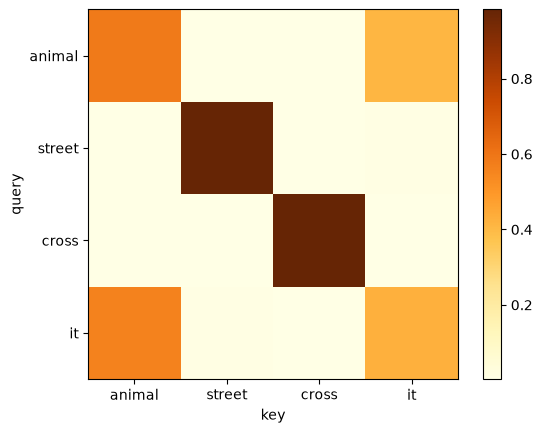

$\sqrt{d}$ 로 나누지 않으면? 칸마다 평균 0, 분산 1 인 무작위 벡터의 내적은 표준편차가 $\sqrt{d}$. 칸이 많으면 점수가 커지고 softmax 가 한 단어에 몰린다.

In [ ]:
rng = np.random.default_rng(0)
for d in [3, 64, 512]:
    q, K = rng.normal(size=d), rng.normal(size=(10, d))
    raw = K @ q
    print(f"d = {d:3d}: std of q.k = {raw.std():5.1f}   max weight without sqrt(d): {softmax(raw).max():.2f}"
          f"   with sqrt(d): {softmax(raw / np.sqrt(d)).max():.2f}")

**예상 결과**

```
d =   3: std of q.k =   0.4   max weight without sqrt(d): 0.18   with sqrt(d): 0.14
d =  64: std of q.k =   8.1   max weight without sqrt(d): 0.74   with sqrt(d): 0.33
d = 512: std of q.k =  23.8   max weight without sqrt(d): 0.94   with sqrt(d): 0.19
```

## 파트 2. Seq2Seq + 어텐션

지난 시간의 GRU 인코더-디코더에서, 디코더의 메모 $\mathbf{s}_k$ 를 쿼리로, 인코더의 모든 칸 $\mathbf{h}_1, \dots, \mathbf{h}_T$ 를 키 · 밸류로 쓴다. 맥락 벡터 $\sum_j \alpha_j \mathbf{h}_j$ 를 $\mathbf{s}_k$ 옆에 붙여 다음 글자를 고른다 (Luong 2015 의 내적 어텐션).

In [ ]:
class Seq2Seq(nn.Module):
    def __init__(self, n_src, n_tgt, hidden, use_attention):
        super().__init__()
        self.use_attention = use_attention
        self.src_emb, self.tgt_emb = nn.Embedding(n_src, hidden), nn.Embedding(n_tgt, hidden)
        self.encoder = nn.GRU(hidden, hidden, batch_first=True)
        self.decoder = nn.GRU(hidden, hidden, batch_first=True)
        self.out = nn.Linear(2 * hidden if use_attention else hidden, n_tgt)

    def attend(self, H, s):
        if not self.use_attention:
            return self.out(s), None
        scores = s @ H.transpose(1, 2)                   # (batch, output steps, input steps)
        alpha = None  # TODO: weights over the input positions
        context = None  # TODO: weighted sum of encoder states
        return self.out(torch.cat([s, context], -1)), alpha

    def forward(self, x, y_in):
        H, h = self.encoder(self.src_emb(x))
        s, _ = self.decoder(self.tgt_emb(y_in), h)
        return self.attend(H, s)[0]

    @torch.no_grad()
    def greedy(self, x, n_steps, bos=1):
        H, h = self.encoder(self.src_emb(x))
        t = torch.full((x.shape[0], 1), bos); outs, alphas = [], []
        for _ in range(n_steps):
            s, h = self.decoder(self.tgt_emb(t), h)
            logits, alpha = self.attend(H, s)
            t = logits.argmax(-1); outs.append(t); alphas.append(alpha)
        return torch.cat(outs, 1), (torch.cat(alphas, 1) if self.use_attention else None)

In [ ]:
def train_copy(use_attention, hidden=32, steps=4000):
    torch.manual_seed(0); g = torch.Generator().manual_seed(0)
    model = Seq2Seq(12, 13, hidden, use_attention)       # input: 0 pad, 1..10 digits / output: 0 pad, 1 <s>, 2 </s>, 3..12 digits
    opt = torch.optim.Adam(model.parameters(), 3e-3)
    for step in range(steps):
        n = int(torch.randint(5, 31, (1,), generator=g))
        d = torch.randint(0, 10, (64, n), generator=g)
        x, y = d + 1, d + 3
        y_in = torch.cat([torch.ones(64, 1, dtype=torch.long), y], 1)[:, :-1]
        loss = nn.functional.cross_entropy(model(x, y_in).reshape(-1, 13), y.reshape(-1))
        opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
    return model

def copy_accuracy(model, lengths):
    acc = []
    for n in lengths:
        d = torch.randint(0, 10, (500, n), generator=torch.Generator().manual_seed(n))
        pred, _ = model.greedy(d + 1, n)
        acc.append(((pred - 3) == d).float().mean().item() * 100)
    return acc

lengths = [5, 10, 15, 20, 25, 30, 40, 50]                 # trained on 5 ~ 30 only
models = {}
for use_attention in [False, True]:
    name = "attention" if use_attention else "plain"
    models[name] = train_copy(use_attention)
    acc = copy_accuracy(models[name], lengths)
    print(f"{name:9s}", [round(a) for a in acc])
    plt.plot(lengths, acc, "o-", label=name)
plt.axvspan(32, 52, color="0.93"); plt.axhline(10, ls=":", color="gray")
plt.xlabel("sequence length"); plt.ylabel("digits correct (%)"); plt.legend(); plt.show()

**예상 결과**

```
plain     [93, 60, 42, 32, 27, 24, 20, 18]
attention [100, 100, 99, 99, 98, 97, 93, 88]
```

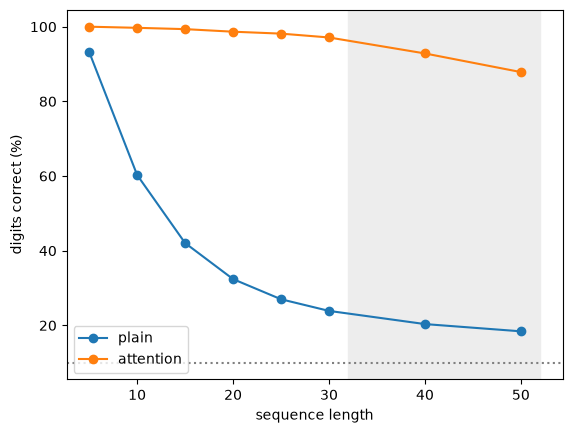

## 파트 3. 어텐션 지도

길이 12 숫자열 하나를 베끼며, 출력 숫자 (행) 가 입력 숫자 (열) 를 보는 비율 $\alpha$ 를 그린다.

In [ ]:
def plot_attention_map(model, digits):
    x = torch.tensor([digits]) + 1
    pred, alpha = model.greedy(x, len(digits))
    plt.imshow(alpha[0].numpy(), cmap="YlOrBr", vmin=0, vmax=1)
    plt.xticks(range(len(digits)), digits); plt.yticks(range(len(digits)), (pred[0] - 3).tolist())
    plt.xlabel("input digit (key)"); plt.ylabel("output digit (query)"); plt.show()
    return alpha[0].argmax(-1).tolist()

print("most-attended input position per output:", plot_attention_map(models["attention"], [1, 9, 1, 0, 1, 8, 2, 8, 5, 0, 9, 5]))

**예상 결과**

```
most-attended input position per output: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
```

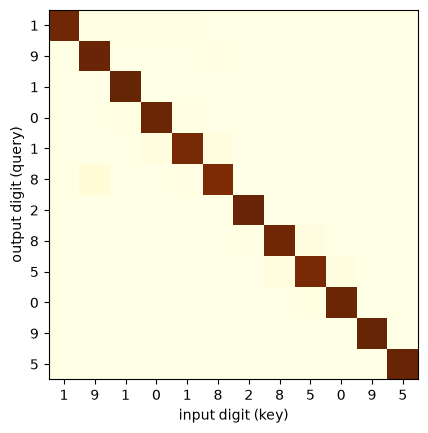

**확인 질문**
1. 파트 1 에서 "it" 벡터를 `[0.3, 2.8, 0]` 으로 바꾸면 비율은 어떻게 바뀌나?
2. 파트 1 의 $\sqrt{d}$ 실험에서, 나누지 않을 때 최대 비율이 1 에 가까워지면 학습에 왜 나쁜가?
3. 파트 2 에서 학습 때 없던 길이 40 · 50 에서 두 모델은 어떻게 다른가? 왜 그럴까?
4. (도전) 입력을 거꾸로 넣어 (`d.flip(1) + 1`) 다시 학습하면 어텐션 지도는 어떤 모양이 될까?